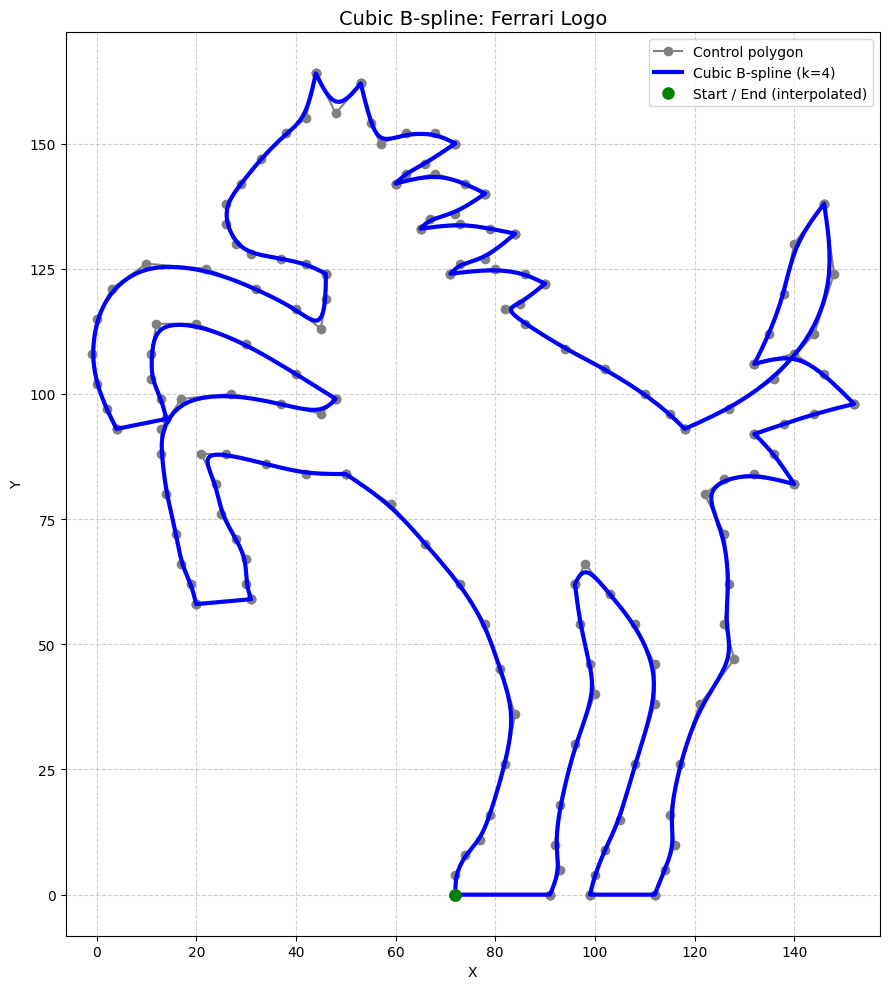


CONTROL POINTS (copy these):
[
    (72.0000, 0.0000),
    (72.0000, 0.0000),
    (72.0000, 0.0000),
    (72.0000, 4.0000),
    (74.0000, 8.0000),
    (77.0000, 11.0000),
    (79.0000, 16.0000),
    (82.0000, 26.0000),
    (84.0000, 36.0000),
    (81.0000, 45.0000),
    (78.0000, 54.0000),
    (73.0000, 62.0000),
    (66.0000, 70.0000),
    (59.0000, 78.0000),
    (50.0000, 84.0000),
    (50.0000, 84.0000),
    (50.0000, 84.0000),
    (42.0000, 84.0000),
    (34.0000, 86.0000),
    (26.0000, 88.0000),
    (21.0000, 88.0000),
    (24.0000, 82.0000),
    (25.0000, 76.0000),
    (28.0000, 71.0000),
    (30.0000, 67.0000),
    (30.0000, 62.0000),
    (31.0000, 59.0000),
    (31.0000, 59.0000),
    (31.0000, 59.0000),
    (20.0000, 58.0000),
    (20.0000, 58.0000),
    (20.0000, 58.0000),
    (19.0000, 62.0000),
    (17.0000, 66.0000),
    (16.0000, 72.0000),
    (14.0000, 80.0000),
    (13.0000, 88.0000),
    (13.0000, 93.0000),
    (17.0000, 99.0000),
    (27.0000, 100.0000),
    (37.0000

In [5]:
"""
================================================================
CUBIC B-SPLINE CURVE DESIGNER (k=4)
================================================================
HOW TO USE:
1. Edit the 'control_points' list below with your own (x, y) points.
2. Run this script.
3. Adjust points until the curve matches your silhouette.
4. The final knot vector is printed in the console – copy it for your report.

ADVANCED: To test a sharp 90-degree corner, change RUN_SHARP_DEMO = True.
================================================================
"""

import numpy as np
import matplotlib.pyplot as plt



#  B-SPLINE (DO NOT EDIT)


def basis_function(i, k, t, knots):
    """Cox-de Boor recursive evaluation of the i-th B-spline basis function."""
    if k == 1:
        # Include upper boundary for the terminal knot (t == knots[-1])
        if t == knots[-1]:
            return 1.0 if (knots[i] <= t <= knots[i + 1] and knots[i] < knots[i + 1]) else 0.0
        return 1.0 if (knots[i] <= t < knots[i + 1]) else 0.0
    else:
        term1 = 0.0
        denom1 = knots[i + k - 1] - knots[i]
        if denom1 != 0:
            term1 = (t - knots[i]) / denom1 * basis_function(i, k - 1, t, knots)

        term2 = 0.0
        denom2 = knots[i + k] - knots[i + 1]
        if denom2 != 0:
            term2 = (knots[i + k] - t) / denom2 * basis_function(i + 1, k - 1, t, knots)

        return term1 + term2


def generate_open_uniform_knots(n_ctrl, k):
    """
    Generate an open-uniform knot vector for a B-spline.
    - First and last knots are repeated 'k' times (endpoint interpolation).
    - Interior knots are equally spaced.
    """
    if n_ctrl < k:
        raise ValueError(f"Need at least {k} control points for order {k}. Got {n_ctrl}.")

    num_knots = n_ctrl + k
    knots = np.zeros(num_knots)
    knots[k:] = 1.0

    n_interior = num_knots - 2 * k
    if n_interior > 0:
        interior = np.linspace(0, 1, n_interior + 2)[1:-1]
        knots[k:-k] = interior

    return knots


def b_spline_curve(control_points, k=4, num_samples=300, knots=None):
    """
    Evaluate a B-spline curve from control points.
    - If `knots` is None, an open-uniform knot vector is generated automatically.
    - Provide your own knots to create sharp corners (repeat interior knots).
    Returns:
        - curve_points: array of sampled (x, y) points on the smooth curve.
        - knots: the knot vector used (printed for the student's report).
    """
    ctrl = np.asarray(control_points)
    n_ctrl = ctrl.shape[0]

    if ctrl.ndim != 2 or ctrl.shape[1] != 2:
        raise ValueError("Control points must be a list of (x, y) pairs.")

    if knots is None:
        knots = generate_open_uniform_knots(n_ctrl, k)
    else:
        knots = np.asarray(knots)
        if len(knots) != n_ctrl + k:
            raise ValueError(f"Knot length must be n_ctrl + k = {n_ctrl+k}. Got {len(knots)}.")

    t_vals = np.linspace(0, 1, num_samples)
    curve = np.zeros((num_samples, 2))

    for idx, t in enumerate(t_vals):
        pt = np.zeros(2)
        for i in range(n_ctrl):
            pt += basis_function(i, k, t, knots) * ctrl[i]
        curve[idx] = pt

    return curve, knots


# ================================================================
#  STUDENT INPUT: CHOOSE YOUR CASE
# ================================================================

RUN_SHARP_DEMO = False  

if RUN_SHARP_DEMO:
    # ============================================================
    #  CASE 1: SHARP 90-DEGREE BEND (DEMO)
    #  - Control points form an "L" shape.
    #  - Custom knot vector repeats the interior knot 3 times
    #    (multiplicity = k-1 = 3) to force a tangent discontinuity.
    # ============================================================
    print("\n" + "="*60)
    print("  SHARP 90-DEGREE CORNER DEMO")
    print("  (Interior knot repeated 3 times to create a kink)")
    print("="*60)

    # Control points forming an L-shape
    control_points = [
        (0.0, 0.0),   
        (3.0, 0.0),   
        (3.0, 3.0),   
        (3.0, 6.0),   
        (6.0, 6.0),   
    ]

    
    custom_knots = [0.0, 0.0, 0.0, 0.0,   
                    0.5, 0.5, 0.5,      
                    1.0, 1.0]           

    curve, knots = b_spline_curve(control_points, k=4, num_samples=300, knots=custom_knots)

else:
    control_points = [
        (72, 0), (72, 0), (72, 0), (72, 4),
        (74, 8), (77, 11), (79, 16), (82, 26),
        (84, 36), (81, 45), (78, 54), (73, 62),
        (66, 70), (59, 78), (50, 84), (50, 84),
        (50, 84), (42, 84), (34, 86), (26, 88),
        (21, 88), (24, 82), (25, 76), (28, 71),
        (30, 67), (30, 62), (31, 59), (31, 59),
        (31, 59), (20, 58), (20, 58), (20, 58),
        (19, 62), (17, 66), (16, 72), (14, 80),
        (13, 88), (13, 93), (17, 99), (27, 100),
        (37, 98), (45, 96), (48, 99), (48, 99),
        (48, 99), (40, 104), (30, 110), (20, 114),
        (12, 114), (11, 108), (11, 103), (13, 99),
        (14, 95), (14, 95), (14, 95), (4, 93),
        (4, 93), (4, 93), (2, 97), (0, 102),
        (-1, 108), (0, 115), (3, 121), (10, 126),
        (22, 125), (32, 121), (40, 117), (45, 113),
        (46, 119), (46, 124), (46, 124), (46, 124),
        (42, 126), (37, 127), (31, 128), (28, 130),
        (26, 134), (26, 138), (29, 142), (33, 147),
        (38, 152), (42, 155), (44, 164), (44, 164),
        (44, 164), (48, 156), (53, 162), (53, 162),
        (53, 162), (55, 154), (57, 150), (62, 152),
        (68, 152), (72, 150), (72, 150), (72, 150),
        (66, 146), (62, 144), (60, 142), (60, 142),
        (60, 142), (68, 144), (74, 142), (78, 140),
        (78, 140), (78, 140), (72, 136), (67, 135),
        (65, 133), (65, 133), (65, 133), (73, 134),
        (79, 133), (84, 132), (84, 132), (84, 132),
        (78, 127), (73, 126), (71, 124), (71, 124),
        (71, 124), (80, 125), (86, 124), (90, 122),
        (90, 122), (90, 122), (85, 118), (82, 117),
        (86, 114), (94, 109), (102, 105), (110, 100),
        (115, 96), (118, 93), (118, 93), (118, 93),
        (127, 97), (136, 103), (144, 112), (148, 124),
        (146, 138), (146, 138), (146, 138), (140, 130),
        (138, 120), (135, 112), (132, 106), (132, 106),
        (132, 106), (140, 108), (146, 104), (152, 98),
        (152, 98), (152, 98), (144, 96), (138, 94),
        (132, 92), (132, 92), (132, 92), (136, 88),
        (140, 82), (140, 82), (140, 82), (132, 84),
        (126, 83), (122, 80), (126, 72), (127, 62),
        (126, 54), (128, 47), (121, 38), (117, 26),
        (115, 16), (116, 10), (114, 5), (112, 0),
        (112, 0), (112, 0), (99, 0), (99, 0),
        (99, 0), (100, 4), (102, 9), (105, 15),
        (108, 26), (112, 38), (112, 46), (108, 54),
        (103, 60), (98, 66), (96, 62), (96, 62),
        (96, 62), (97, 54), (99, 46), (100, 40),
        (96, 30), (93, 18), (92, 10), (93, 5),
        (91, 0), (91, 0), (91, 0), (72, 0),
        (72, 0), (72, 0)
    ]
    curve, knots = b_spline_curve(control_points, k=4, num_samples=1200, knots=None)


# ================================================================
#  PLOT THE RESULT
# ================================================================

plt.figure(figsize=(9, 10))
cp = np.array(control_points)

# Control polygon (gray dashed)
plt.plot(cp[:, 0], cp[:, 1], 'o-', color='gray', markersize=6,
         linewidth=1.5, label='Control polygon')

# B-spline curve (blue)
plt.plot(curve[:, 0], curve[:, 1], 'b-', linewidth=3,
         label='Cubic B-spline (k=4)')


# Mark the start and end points (which lie exactly on the curve)
plt.plot(cp[0, 0], cp[0, 1], 'go', markersize=8, label='Start / End (interpolated)')
plt.plot(cp[-1, 0], cp[-1, 1], 'go', markersize=8)

# If it's the sharp demo, highlight the kink
if RUN_SHARP_DEMO:
    plt.plot(3.0, 3.0, 'ro', markersize=10, label='Sharp corner (kink)')
    plt.title("Cubic B-spline with Sharp 90° Corner (Knot multiplicity = 3)", fontsize=14)
else:
    plt.title("Cubic B-spline: Ferrari Logo", fontsize=14)

plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.axis('equal')  # Keeps proportions correct
plt.tight_layout()
# Save the plot as a JPG file
plt.savefig('b_spline_curve.jpg', format='jpg', dpi=300, bbox_inches='tight')
plt.show()


print("\nCONTROL POINTS (copy these):")
print("[")
for pt in control_points:
    print(f"    ({pt[0]:.4f}, {pt[1]:.4f}),")
print("]")

print("\nKNOT VECTOR (copy this):")
print("[", end="")
for i, val in enumerate(knots):
    if i == len(knots) - 1:
        print(f"{val:.4f}", end="")
    else:
        print(f"{val:.4f}, ", end="")
print("]")

if RUN_SHARP_DEMO:
    print("\nNOTE: The interior knot (0.5) was repeated 3 times.")
    print("This creates multiplicity = k-1 = 3, which forces a C^0 discontinuity (sharp corner).")
else:
    print("\nNOTE: Open-uniform knot vector used (fully smooth C^2 continuous).")

In [6]:
!pip install numpy matplotlib


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
